# EDA – Financial Inclusion in Africa (Andi)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

DATA = "../../data/raw/"
FIG = "figures/"

# 1.Erster Überblick
##### Ziel: verstehen, was in den Daten steckt, bevor du etwas auswertest.

In [4]:
train = pd.read_csv(DATA + "Train.csv")
test = pd.read_csv(DATA + "Test.csv")
defs = pd.read_csv(DATA + "VariableDefinitions.csv")

print("Train:", train.shape, "| Test:", test.shape)
display(defs)
display(train.head())
train.info()

Train: (23524, 13) | Test: (10086, 12)


,Variable Definitions,Unnamed: 1
0,country,Country interviewee is in.
1,year,Year survey was done in.
2,uniqueid,Unique identifier for each interviewee
3,location_type,"Type of location: Rural, Urban"
4,cellphone_access,"If interviewee has access to a cellphone: Yes, No"
5,household_size,Number of people living in one house
6,age_of_respondent,The age of the interviewee
7,gender_of_respondent,"Gender of interviewee: Male, Female"
8,relationship_with_head,The interviewee’s relationship with the head o...
9,marital_status,The martial status of the interviewee: Married...


,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,Yes,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,No,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,Yes,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,No,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,No,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed


<class 'pandas.DataFrame'>
RangeIndex: 23524 entries, 0 to 23523
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   country                 23524 non-null  str  
 1   year                    23524 non-null  int64
 2   uniqueid                23524 non-null  str  
 3   bank_account            23524 non-null  str  
 4   location_type           23524 non-null  str  
 5   cellphone_access        23524 non-null  str  
 6   household_size          23524 non-null  int64
 7   age_of_respondent       23524 non-null  int64
 8   gender_of_respondent    23524 non-null  str  
 9   relationship_with_head  23524 non-null  str  
 10  marital_status          23524 non-null  str  
 11  education_level         23524 non-null  str  
 12  job_type                23524 non-null  str  
dtypes: int64(3), str(10)
memory usage: 2.3 MB


## Fazit: Erster Überblick

### Größe und Struktur
- **Train:** 23.524 Zeilen × 13 Spalten, **Test:** 10.086 Zeilen × 12 Spalten. Beides entspricht den erwarteten Dimensionen.
- Der Test-Datensatz hat genau eine Spalte weniger, nämlich die Zielvariable `bank_account`. Er enthält also **keine Labels**. Für Training, Validierung und Evaluation arbeiten wir deshalb ausschließlich mit `Train.csv` und teilen es selbst auf.
- Der Datensatz ist mit ca. 2,3 MB klein, Rechenzeit ist kein Engpass.

### Datentypen

| Typ | Spalten |
|---|---|
| Numerisch (int64, 3) | `year`, `household_size`, `age_of_respondent` |
| Text/kategorial (str, 10) | `country`, `uniqueid`, `bank_account`, `location_type`, `cellphone_access`, `gender_of_respondent`, `relationship_with_head`, `marital_status`, `education_level`, `job_type` |

- Alle 13 Spalten haben 23.524 Nicht-Null-Werte, es gibt also keine fehlenden Werte (Details in Schritt 2).
- `year` ist als Zahl gespeichert, enthält aber nur drei Befragungsjahre (2016, 2017, 2018). Wir behandeln es als **Kategorie**, nicht als stetiges Merkmal.
- `bank_account`, `cellphone_access`, `location_type` und `gender_of_respondent` sind binäre Textspalten. Für die Modellierung wandeln wir sie in 0/1 um.

### Rolle der Spalten
- **Zielvariable:** `bank_account` (Yes/No).
- **Keine Features:** `uniqueid` ist nur eine Kennung ("uniqueid_1", "uniqueid_2", ...). Sie enthält keine inhaltliche Information und wird nicht für das Modell genutzt.
- **Features (11):** `country`, `year`, `location_type`, `cellphone_access`, `household_size`, `age_of_respondent`, `gender_of_respondent`, `relationship_with_head`, `marital_status`, `education_level`, `job_type`. Davon sind zwei numerisch (`household_size`, `age_of_respondent`) und neun kategorial (inkl. `year`).

### Variablendefinitionen
- Die Datei beschreibt 12 Variablen, **die Zielvariable `bank_account` fehlt** in der Liste. Ihre Bedeutung entnehmen wir der Wettbewerbsbeschreibung: Person hat ein Bankkonto oder nutzt eines.
- Beim Einlesen heißen die Spalten "Variable Definitions" und "Unnamed: 1", die Datei hat also keine saubere Kopfzeile. Für unsere Feature-Dokumentation ist das unkritisch, wir lesen sie nur zur Orientierung.
- In der Definitionsdatei steht "martial_status", im Datensatz heißt die Spalte `marital_status`. Das ist ein Tippfehler in der Dokumentation und kein Problem in den Daten.

### Auffälligkeiten in den ersten Zeilen
- Alle ersten fünf Zeilen stammen aus Kenia und dem Jahr 2018. Die Daten sind also **nach Land und Jahr sortiert** und nicht zufällig gemischt. Bei einem einfachen Split ohne Mischen würden Training und Validierung aus unterschiedlichen Ländern bestehen. Wir verwenden deshalb immer einen **gemischten, stratifizierten** Split (`shuffle=True`, `stratify=y`, fester Seed).
- Die `uniqueid` zählt offenbar pro Land von vorn. Wir prüfen Duplikate deshalb über die Kombination `uniqueid` + `country` (Ergebnis in Schritt 2: keine Duplikate).

### Konsequenzen für die weiteren Schritte
- Zielvariable in 0/1 umkodieren (`target`) und `uniqueid` ausschließen.
- `year` als Kategorie behandeln.
- Feature-Dokumentation anlegen (Typ, Beschreibung, Ausprägungen, Auffälligkeiten), ergänzt um `bank_account`, das in den Definitionen fehlt.
- Nur `Train.csv` für Analyse und Modellbewertung nutzen, `Test.csv` erst für eine mögliche Abgabe auf Zindi.

# 2. Datenqualität prüfen
##### Ziel: Fehler finden, die später Ergebnisse verfälschen würden.

In [5]:
# 1) Fehlende Werte
print(train.isnull().sum())

# 2) Duplikate
print("Komplett doppelte Zeilen:", train.duplicated().sum())
print("Doppelte uniqueid+country:", train.duplicated(subset=["uniqueid", "country"]).sum())

# 3) Numerische Spalten: Wertebereich
display(train[["household_size", "age_of_respondent"]].describe())

# 4) Kategorien: alle Ausprägungen ansehen
for col in train.select_dtypes("object").columns.drop("uniqueid"):
    print(f"\n{col}:\n", train[col].value_counts(dropna=False))

# 5) Gibt es Kategorien im Test, die im Train fehlen?
for col in test.select_dtypes("object").columns.drop("uniqueid"):
    diff = set(test[col]) - set(train[col])
    if diff:
        print("Nur im Test:", col, diff)

country                   0
year                      0
uniqueid                  0
bank_account              0
location_type             0
cellphone_access          0
household_size            0
age_of_respondent         0
gender_of_respondent      0
relationship_with_head    0
marital_status            0
education_level           0
job_type                  0
dtype: int64
Komplett doppelte Zeilen: 0
Doppelte uniqueid+country: 0


,household_size,age_of_respondent
count,23524.000000,23524.000000
mean,3.797483,38.805220
std,2.227613,16.520569
min,1.000000,16.000000
25%,2.000000,26.000000
50%,3.000000,35.000000
75%,5.000000,49.000000
max,21.000000,100.000000



country:
 country
Rwanda      8735
Tanzania    6620
Kenya       6068
Uganda      2101
Name: count, dtype: int64

bank_account:
 bank_account
No     20212
Yes     3312
Name: count, dtype: int64

location_type:
 location_type
Rural    14343
Urban     9181
Name: count, dtype: int64

cellphone_access:
 cellphone_access
Yes    17454
No      6070
Name: count, dtype: int64

gender_of_respondent:
 gender_of_respondent
Female    13877
Male       9647
Name: count, dtype: int64

relationship_with_head:
 relationship_with_head
Head of Household      12831
Spouse                  6520
Child                   2229
Parent                  1086
Other relative           668
Other non-relatives      190
Name: count, dtype: int64

marital_status:
 marital_status
Married/Living together    10749
Single/Never Married        7983
Widowed                     2708
Divorced/Seperated          2076
Dont know                      8
Name: count, dtype: int64

education_level:
 education_level
Primary education  

/var/folders/6c/n2j0ytp54hv93stz2bz3lvbr0000gn/T/ipykernel_16233/1382849311.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in train.select_dtypes("object").columns.drop("uniqueid"):
/var/folders/6c/n2j0ytp54hv93stz2bz3lvbr0000gn/T/ipykernel_16233/1382849311.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See http

## Fazit: Datenqualität

### Übersicht der Prüfungen

| Prüfung | Ergebnis | Entscheidung |
|---|---|---|
| Fehlende Werte | 0 in allen 13 Spalten | Keine Imputation nötig |
| Komplett doppelte Zeilen | 0 | Keine Bereinigung nötig |
| Doppelte Kombination uniqueid + country | 0 | Kombination ist eindeutig, uniqueid wird nur als ID genutzt, nicht als Feature |
| Unplausible Werte household_size | Wertebereich 1 bis 21 | Behalten (siehe unten) |
| Unplausible Werte age_of_respondent | Wertebereich 16 bis 100 | Behalten (siehe unten) |
| Seltene Kategorien / Sammelkategorien | Vorhanden (siehe unten) | Im Preprocessing zusammenfassen |
| Kategorien nur im Test, nicht im Train | [Ergebnis des Checks eintragen: keine / welche] | [...] |

### Fehlende Werte und Duplikate
Der Datensatz (23.524 Zeilen) ist formal sauber: Es gibt weder fehlende Werte noch doppelte Zeilen. Zu beachten ist, dass "fehlend" hier teils als **Kategorie** kodiert ist, etwa "Dont Know/Refuse to answer" (126 Fälle) bei `job_type`. Das sind inhaltlich fehlende Angaben, auch wenn pandas sie nicht als NaN zählt. [Entsprechende Ausprägungen bei marital_status und education_level ergänzen, falls vorhanden.]

### Numerische Spalten

| | household_size | age_of_respondent |
|---|---|---|
| Mittelwert | 3,80 | 38,8 |
| Median | 3 | 35 |
| 25 % / 75 % | 2 / 5 | 26 / 49 |
| Minimum / Maximum | 1 / 21 | 16 / 100 |
| Standardabweichung | 2,23 | 16,5 |

- **household_size:** Das Minimum von 1 ist plausibel (Einpersonenhaushalt). Das Maximum von 21 liegt weit über dem Median von 3, ist bei Großfamilien in der Region aber denkbar. Mittelwert (3,80) über Median (3) zeigt die Rechtsschiefe.
- **age_of_respondent:** Das Mindestalter von 16 passt zu einer Erwachsenenbefragung. Das Maximum von 100 ist ungewöhnlich, es ist zu prüfen, ob es sich um eine Obergrenze (Top-Coding) handelt und ob sich dort Fälle häufen.
- **Ausreißergrenzen (1,5 × IQR):** household_size ab ca. 10 Personen, Alter ab ca. 84 Jahren. Es gibt keine unmöglichen Werte wie negative Zahlen oder Alter unter 16, deshalb entfernen wir **keine** Ausreißer. Sie sind vermutlich echte, aber seltene Fälle.

### Kategoriale Spalten
- **country:** Ruanda 8.735 (37,1 %), Tansania 6.620 (28,1 %), Kenia 6.068 (25,8 %), Uganda 2.101 (8,9 %). Uganda ist deutlich unterrepräsentiert.
- **location_type:** Rural 14.343 (61,0 %), Urban 9.181 (39,0 %).
- **cellphone_access:** Yes 17.454 (74,2 %), No 6.070 (25,8 %).
- **Schreibweise und Konsistenz:** Die Kategorien sind einheitlich geschrieben. Auffällig ist nur die uneinheitliche Schreibweise der Sammelkategorien ("Dont know", "Dont Know/Refuse to answer", "Other/Dont know/RTA"), die wir vor dem Modellieren vereinheitlichen.
- **Seltene Kategorien:** Bei `job_type` sind "Formally employed Government" (387, ca. 1,6 %), "Government Dependent" (247, ca. 1,0 %) und "Dont Know/Refuse to answer" (126, ca. 0,5 %) sehr klein. [Weitere seltene Kategorien aus marital_status, education_level und relationship_with_head ergänzen.]

### Konsequenzen für das Preprocessing
- Keine Zeilen entfernen und keine Werte auffüllen, da die Daten vollständig und konsistent sind.
- "Dont know"-Ausprägungen und andere Sammelkategorien zu einer Kategorie "Unbekannt/Sonstige" zusammenfassen.
- Seltene Jobtypen (v. a. die beiden Regierungs-Kategorien) zusammenlegen, damit Modelle und Gruppenquoten stabiler werden.
- Ausreißer bei household_size und Alter behalten. Für lineare Modelle bei household_size ggf. log-Transformation oder Kappung prüfen, baumbasierte Modelle sind robust.
- Altersgruppen bilden (siehe Schritt 5).

# 3.Zielvariable analysieren
##### Ziel: wissen, wie unausgewogen die Klassen sind. Das bestimmt, welche Metriken später sinnvoll sind.

bank_account
No     20212
Yes     3312
Name: count, dtype: int64
bank_account
No     0.859
Yes    0.141
Name: proportion, dtype: float64


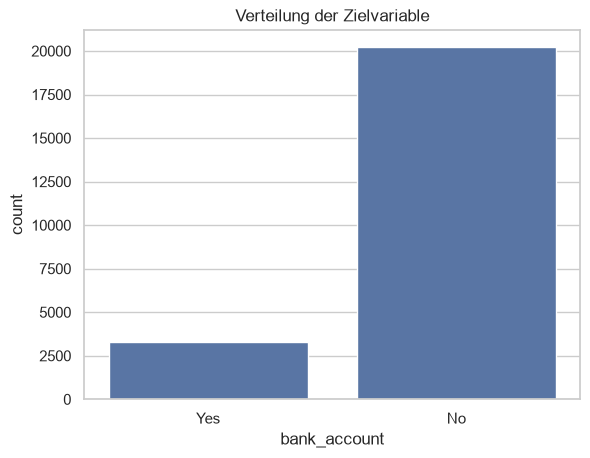

In [6]:
train["target"] = (train["bank_account"] == "Yes").astype(int)

print(train["bank_account"].value_counts())
print(train["bank_account"].value_counts(normalize=True).round(3))

ax = sns.countplot(data=train, x="bank_account")
ax.set_title("Verteilung der Zielvariable")
plt.savefig(FIG + "00_zielvariable.png", dpi=200, bbox_inches="tight")
plt.show()

## Fazit: Analyse der Zielvariable (bank_account)

**Verteilung**

| Klasse | Anzahl | Anteil |
|---|---|---|
| No (kein Bankkonto) | 20.212 | 85,9 % |
| Yes (Bankkonto) | 3.312 | 14,1 % |
| **Gesamt** | **23.524** | **100 %** |

**Klassenungleichgewicht:** Die Zielvariable ist stark unausgewogen. Auf eine Person mit Bankkonto kommen ca. 6 Personen ohne Konto (Verhältnis ca. 6,1 : 1). Die positive Klasse, die für das Projekt eigentlich interessant ist, ist die Minderheitsklasse.

**Baseline:** Ein Modell, das für alle Befragten "No" vorhersagt, erreicht bereits eine Accuracy von **85,9 %**, ohne irgendetwas zu lernen. Das ist die Referenzmarke, die jedes Modell übertreffen muss. Eine hohe Accuracy allein sagt hier also fast nichts über die Modellqualität aus. Ein einfaches Logistic-Regression-Modell kommt laut einem öffentlichen Tutorial auf ca. 88,7 % und liegt damit nur knapp drei Prozentpunkte über der Baseline (der genaue Wert hängt vom jeweiligen Split ab).

**Konsequenzen für die Modellierung**
- **Metriken:** Accuracy nur zur Einordnung angeben. Als Hauptmetriken eignen sich F1-Score, Precision und Recall der Klasse "Yes" sowie PR-AUC (ergänzend ROC-AUC). Die Confusion Matrix macht sichtbar, wie viele Kontoinhaber das Modell tatsächlich findet.
- **Split:** Train/Validation-Aufteilung und Cross-Validation müssen **stratifiziert** erfolgen, damit der Anteil von ca. 14 % in jeder Teilmenge erhalten bleibt.
- **Umgang mit Imbalance:** Class Weights (`class_weight="balanced"`), Over- oder Undersampling (z. B. SMOTE) und Anpassung der Entscheidungsschwelle sind Optionen, die wir im Modellierungsschritt vergleichen. Resampling nur auf den Trainingsdaten anwenden, nie auf Validierungs- oder Testdaten.
- **Interpretation:** Die Stichprobe von 3.312 positiven Fällen ist für Modelle ausreichend, bei Auswertungen nach kleinen Untergruppen (z. B. nach Land und Jobtyp) bleiben aber oft nur wenige positive Fälle übrig. Gruppenquoten daher immer mit Gruppengröße angeben.
- **Einordnung:** Ein Anteil von 14 % entspricht der Größenordnung, die die Wettbewerbsbeschreibung für den Zugang zu Bankkonten in der Region nennt. Die Stichprobe wirkt hier also plausibel.

# 4. Univariate Analyse, kategoriale Features
##### Ziel: sehen, wie die Stichprobe zusammengesetzt ist.

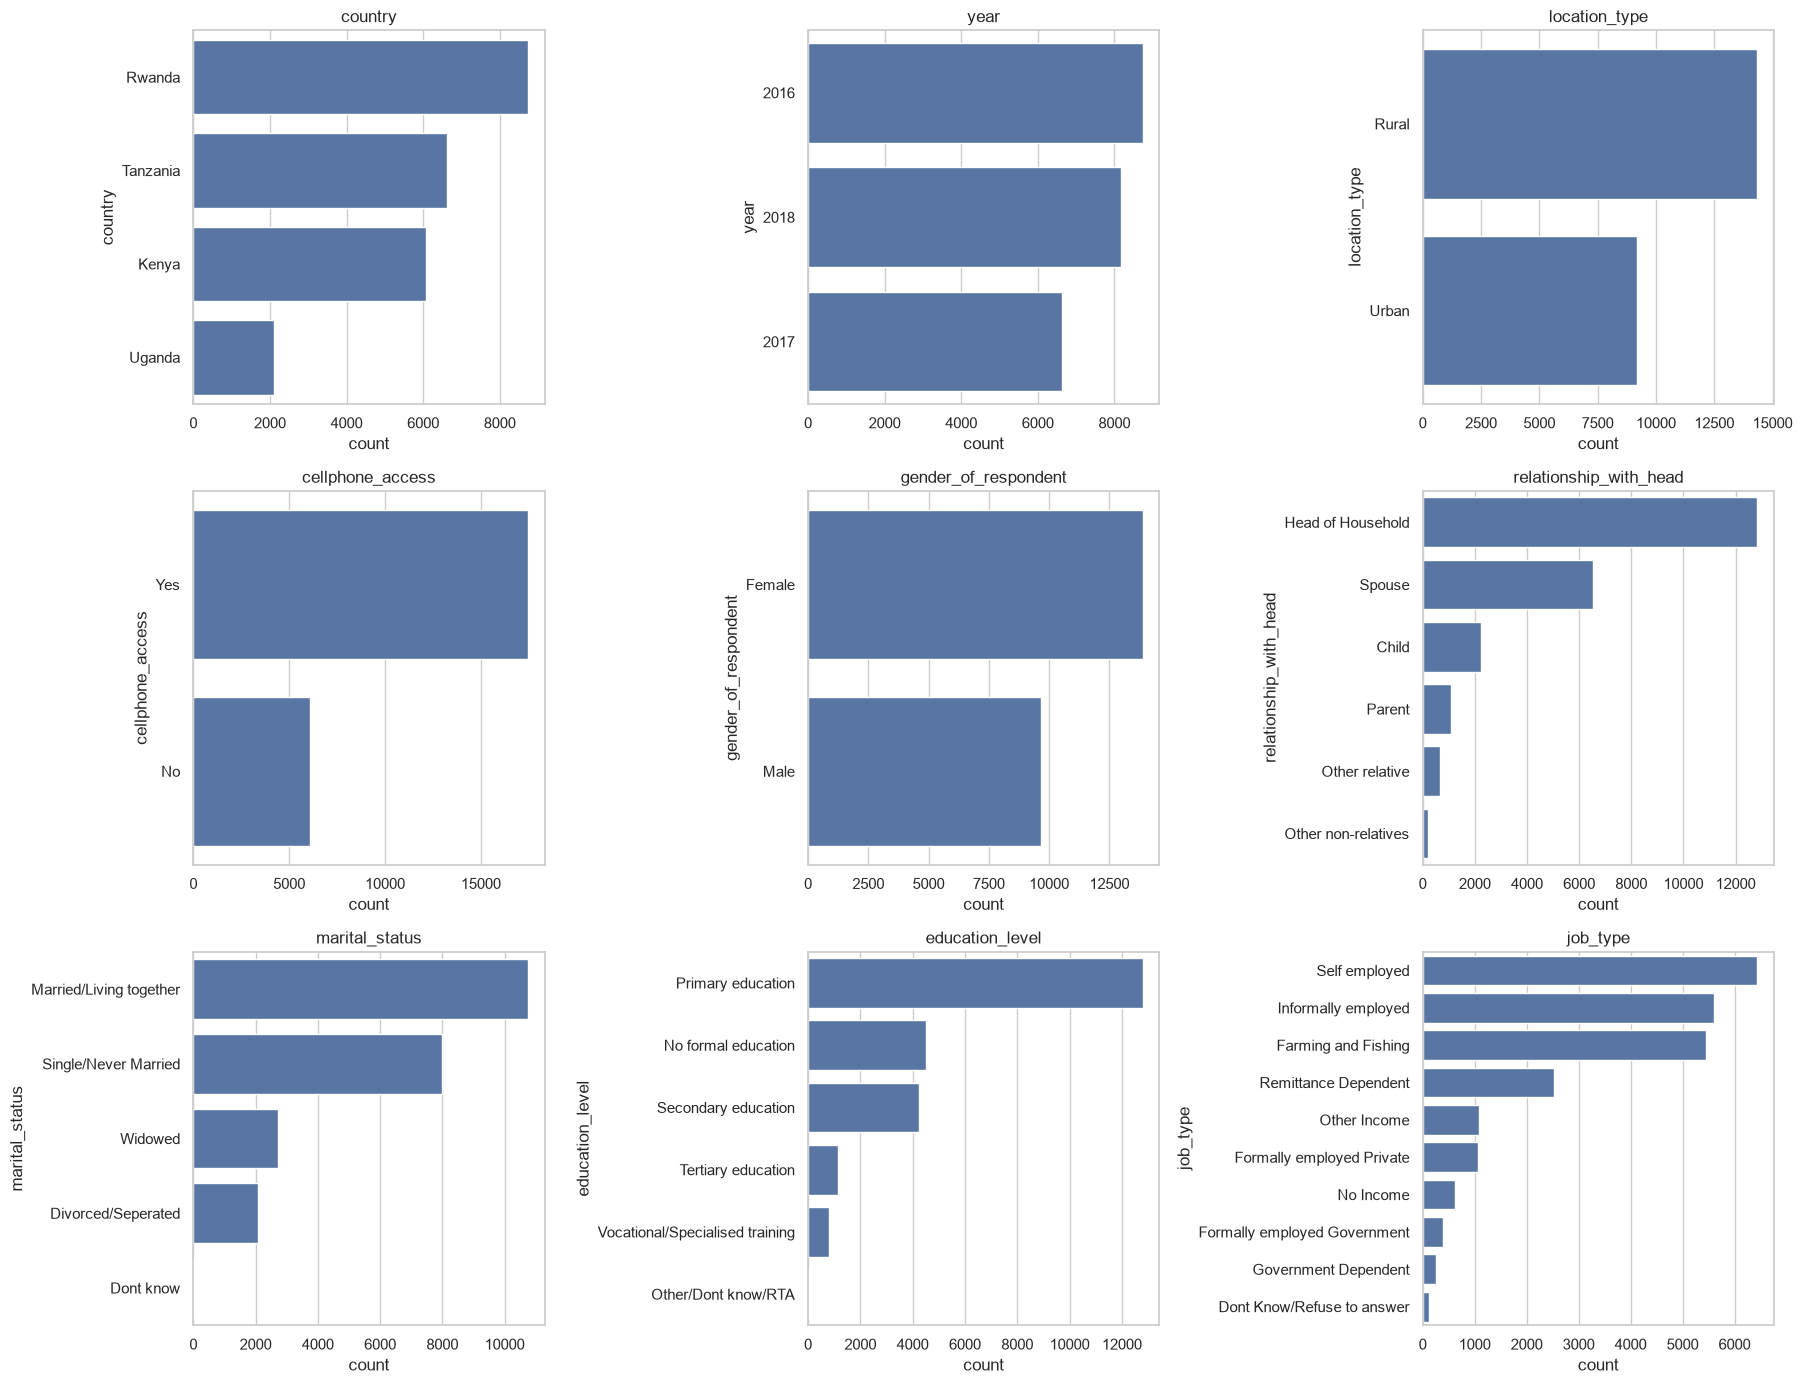

In [7]:
train["year"] = train["year"].astype(str)   # Jahr als Kategorie behandeln

cat_cols = ["country", "year", "location_type", "cellphone_access",
            "gender_of_respondent", "relationship_with_head",
            "marital_status", "education_level", "job_type"]

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.ravel(), cat_cols):
    order = train[col].value_counts().index
    sns.countplot(data=train, y=col, order=order, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(FIG + "01_univariat_kategorial.png", dpi=200)
plt.show()

## Fazit: Univariate Analyse der kategorialen Features

**Gesamteindruck:** Die Stichprobe (23.524 Befragte) ist stark von bestimmten Gruppen geprägt: ländlich, geringe Bildung, überwiegend informelle Arbeit. Einige Kategorien sind so klein, dass spätere Aussagen dort unsicher werden.

**Dominante Gruppen**
- **country:** Ruanda stellt mit ca. 37 % die meisten Befragten, gefolgt von Tansania (ca. 28 %) und Kenia (ca. 26 %). Uganda ist mit ca. 9 % deutlich unterrepräsentiert.
- **year:** Die Befragungen stammen aus 2016, 2017 und 2018. Die Jahreszahlen entsprechen fast genau den Ländergrößen (Ruanda ≈ 2016, Tansania ≈ 2017, Kenia + Uganda ≈ 2018). Das Jahr ist damit vermutlich weitgehend mit dem Land vermischt und liefert kaum eigene Information. (Mit einer Kreuztabelle country × year prüfen.)
- **location_type:** Ca. 61 % wohnen im ländlichen Raum, ca. 39 % in der Stadt.
- **cellphone_access:** Ca. 74 % haben Handyzugang, ca. 26 % nicht.
- **gender_of_respondent:** Frauen sind mit ca. 59 % überrepräsentiert. Die Stichprobe spiegelt die Bevölkerung wohl nicht 1:1 wider.
- **relationship_with_head:** Über die Hälfte (ca. 54 %) sind Haushaltsvorstände, danach folgen Ehepartner (ca. 28 %).
- **marital_status:** Verheiratet bzw. zusammenlebend (ca. 45 %) und ledig (ca. 34 %) machen den Großteil aus.
- **education_level:** Grundschulbildung dominiert mit ca. 54 %. Dazu kommen ca. 19 % ohne formale Bildung und ca. 18 % mit Sekundarbildung.
- **job_type:** Selbstständig, informell beschäftigt sowie Landwirtschaft und Fischerei bilden die drei größten Gruppen (zusammen ca. 75 %). Formelle Beschäftigung ist selten.

**Sehr kleine Gruppen (unter ca. 1 bis 2 %)**
- relationship_with_head: "Other non-relatives"
- marital_status: "Dont know" (kaum sichtbar)
- education_level: "Other/Dont know/RTA" (kaum sichtbar), außerdem Tertiary (ca. 5 %) und Vocational (ca. 3 %) vergleichsweise klein
- job_type: "Formally employed Government", "Government Dependent", "Dont Know/Refuse to answer"

Bei diesen Gruppen sind Quoten später kaum belastbar, und viele Modelle können dort nur schwer lernen.

**Konsequenzen für Preprocessing und Analyse**
- Sehr seltene Kategorien zusammenfassen (z. B. "Dont know"-Ausprägungen zu "Other/Unbekannt", beide Regierungs-Jobtypen zu einer Gruppe).
- year und country auf Redundanz prüfen und ggf. nur eines davon nutzen.
- Bei Quoten pro Gruppe immer die Gruppengröße n mit angeben.
- In den Limitationen erwähnen: Die Stichprobe ist nicht repräsentativ (Frauen, Landbevölkerung und niedrige Bildung überrepräsentiert, Uganda klein).

# 5.Univariate Analyse, numerische Features
##### Ziel: Form der Verteilung und Ausreißer erkennen.

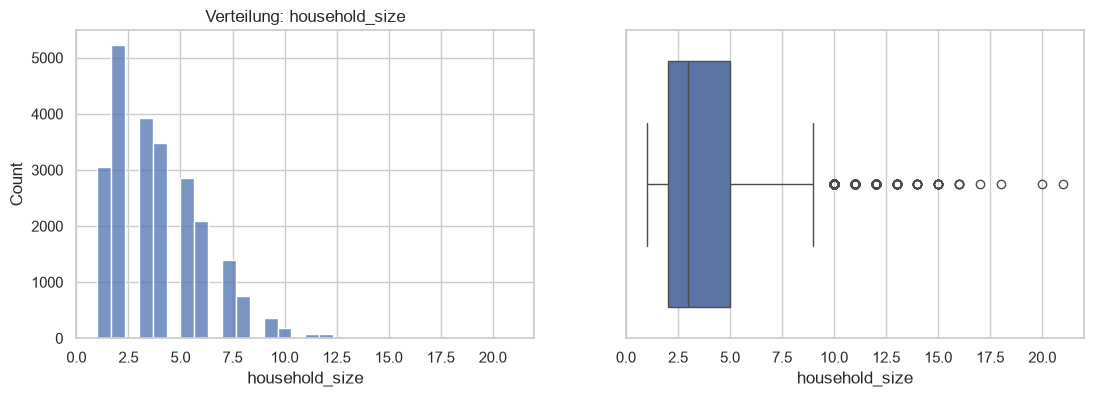

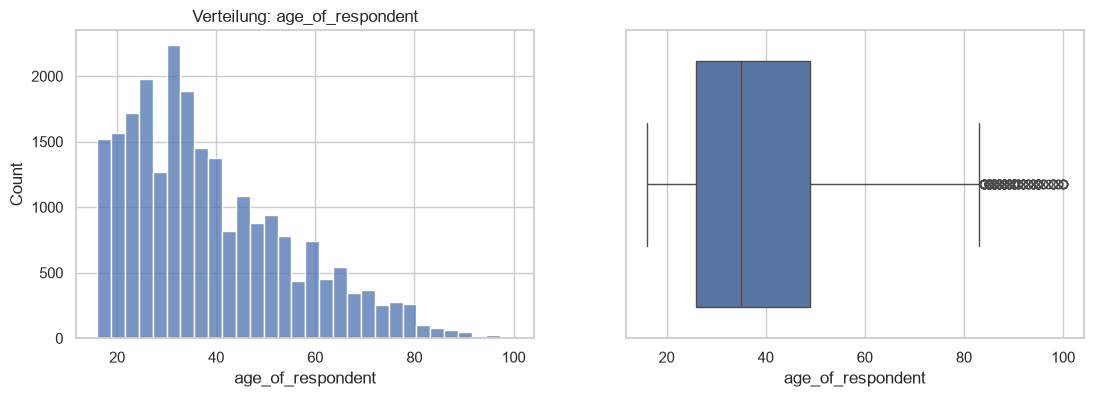

In [8]:
for col in ["household_size", "age_of_respondent"]:
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    sns.histplot(train[col], bins=30, ax=ax[0])
    sns.boxplot(x=train[col], ax=ax[1])
    ax[0].set_title(f"Verteilung: {col}")
    plt.savefig(FIG + f"02_univariat_{col}.png", dpi=200, bbox_inches="tight")
    plt.show()

## Fazit: Univariate Analyse der numerischen Features

### household_size (Haushaltsgröße)

**Form der Verteilung:** Die Verteilung ist deutlich rechtsschief. Die meisten Haushalte sind klein, der Median liegt bei ca. 3 Personen, die mittleren 50 % der Haushalte haben etwa 2 bis 5 Personen. Der häufigste Wert liegt bei ca. 2 Personen, danach nimmt die Häufigkeit mit steigender Größe stetig ab.

**Ausreißer:** Der Boxplot markiert Haushalte ab ca. 10 Personen als Ausreißer (nach der 1,5-IQR-Regel), vereinzelt bis ca. 20 Personen. Das sind wenige Fälle. Große Haushalte mit 10 bis 20 Personen sind in Ostafrika (Großfamilien, mehrere Generationen) plausibel und kein klarer Datenfehler.

**Auffälligkeit im Histogramm:** Die Lücken und ungleichmäßigen Balken entstehen vermutlich durch die Klassenbreite (bins=30) bei ganzzahligen Werten und sind kein echtes Muster in den Daten. Für eine saubere Darstellung sollte `discrete=True` verwendet werden.

### age_of_respondent (Alter)

**Form der Verteilung:** Ebenfalls rechtsschief. Die Befragten sind überwiegend jung bis mittleren Alters: Der Median liegt bei ca. 35 Jahren, die mittleren 50 % zwischen ca. 26 und 49 Jahren. Der Gipfel liegt bei etwa 30 bis 35 Jahren, danach sinkt die Häufigkeit stetig. Das Mindestalter liegt bei ca. 16 Jahren, es wurden also nur Erwachsene und Jugendliche ab 16 befragt.

**Ausreißer:** Als Ausreißer markiert der Boxplot Befragte ab ca. 84 Jahren bis hin zu 100. Das ist ein dichter Streifen am Rand, aber insgesamt ein kleiner Anteil. Hohe Alter sind grundsätzlich plausibel, bei 100 sollte man prüfen, ob der Wert eine Obergrenze (Top-Coding) ist und ob es dort eine Häufung gibt.

**Häufungen bei runden Werten:** Im Histogramm ist ein Ausschlag um 60 Jahre erkennbar, ein typisches Anzeichen für gerundete Altersangaben in Umfragen. Das ist wegen der groben Klassen nur ein Hinweis und sollte mit `value_counts()` auf Einzelwerten bestätigt werden.

### Konsequenzen für Preprocessing und Modellierung

- **Keine Ausreißer entfernen:** Die Extremwerte wirken plausibel, deshalb behalten wir sie. Baumbasierte Modelle (Random Forest, XGBoost) sind dagegen robust, bei linearen Modellen kann eine Transformation (z. B. log) oder Kappung für household_size sinnvoll sein.
- **Altersgruppen bilden:** Wegen der Schiefe und der gerundeten Angaben sind Gruppen (z. B. 16 bis 25, 26 bis 35, ...) für die Analyse der Bankkontoquote besser geeignet als Einzelwerte.
- **Limitation:** Die Stichprobe ist jung und überwiegend in kleinen Haushalten, ältere Menschen und große Haushalte sind entsprechend schwächer vertreten.

# 6. Bankkontoquote nach Gruppen

##### Ziel: der Kern der EDA. Welche Gruppen haben häufiger ein Konto?

,country,quote,n
0,Kenya,0.250659,6068
1,Rwanda,0.114825,8735
2,Tanzania,0.091692,6620
3,Uganda,0.086149,2101


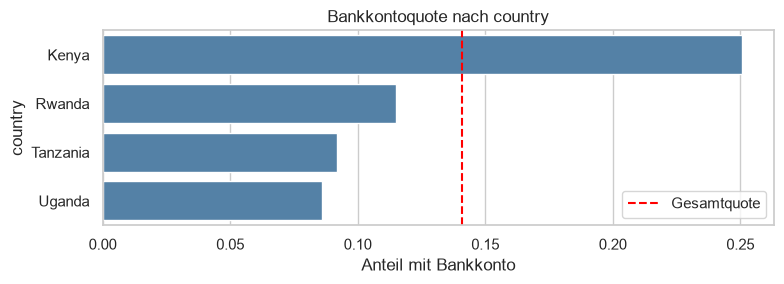

,location_type,quote,n
1,Urban,0.178739,9181
0,Rural,0.116503,14343


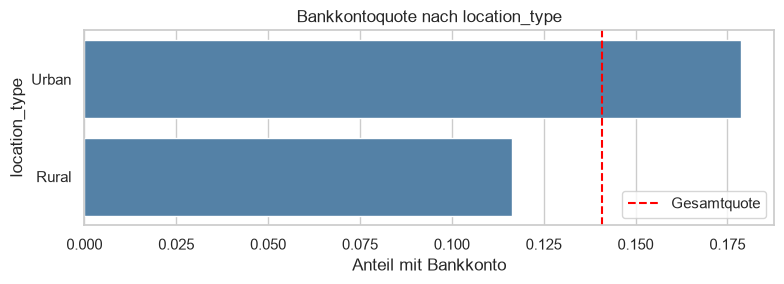

,gender_of_respondent,quote,n
1,Male,0.189696,9647
0,Female,0.106795,13877


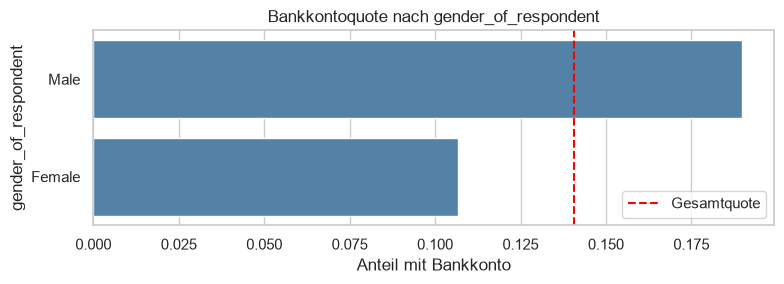

,education_level,quote,n
5,Vocational/Specialised training,0.570361,803
4,Tertiary education,0.510804,1157
1,Other/Dont know/RTA,0.314286,35
3,Secondary education,0.232773,4223
2,Primary education,0.085451,12791
0,No formal education,0.038981,4515


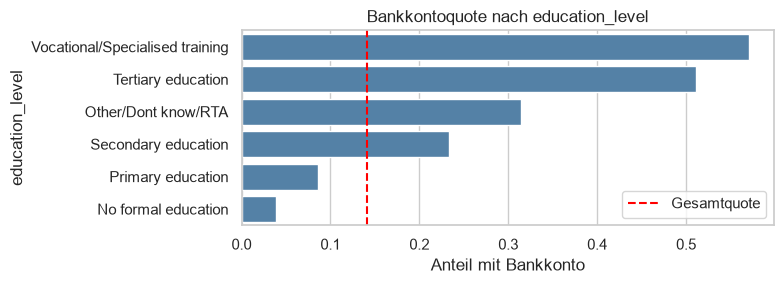

,job_type,quote,n
2,Formally employed Government,0.775194,387
3,Formally employed Private,0.541232,1055
4,Government Dependent,0.202429,247
7,Other Income,0.181481,1080
9,Self employed,0.131738,6437
1,Farming and Fishing,0.116706,5441
0,Dont Know/Refuse to answer,0.111111,126
8,Remittance Dependent,0.094974,2527
5,Informally employed,0.079507,5597
6,No Income,0.020734,627


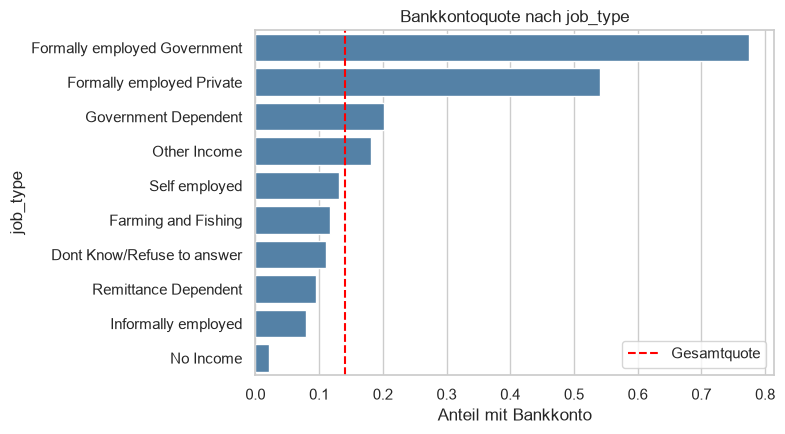

,cellphone_access,quote,n
1,Yes,0.183797,17454
0,No,0.017133,6070


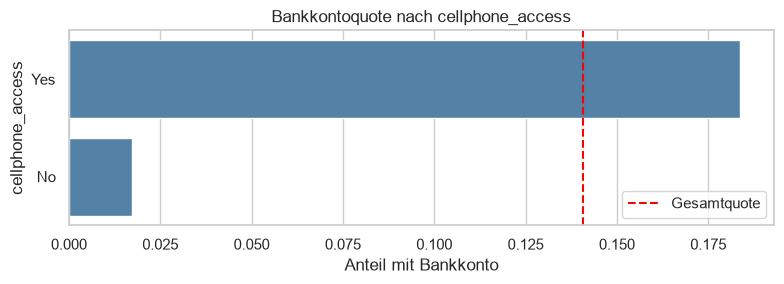

In [9]:
def rate_by(col):
    return (train.groupby(col)["target"]
                 .agg(quote="mean", n="size")
                 .reset_index()
                 .sort_values("quote", ascending=False))

def plot_rate(col):
    d = rate_by(col)
    plt.figure(figsize=(8, max(3, len(d) * 0.45)))
    sns.barplot(data=d, y=col, x="quote", order=d[col], color="steelblue")
    plt.axvline(train["target"].mean(), color="red", ls="--", label="Gesamtquote")
    plt.xlabel("Anteil mit Bankkonto")
    plt.title(f"Bankkontoquote nach {col}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIG + f"03_quote_{col}.png", dpi=200)
    plt.show()

for col in ["country", "location_type", "gender_of_respondent",
            "education_level", "job_type", "cellphone_access"]:
    display(rate_by(col))
    plot_rate(col)

## Fazit: Bankkontoquote nach Gruppen

**Gesamtquote:** 14,1 % (3.312 von 23.524 Befragten). Alle Quoten unten beziehen sich auf diesen Wert.

### Überblick

| Merkmal | Höchste Quote | Niedrigste Quote | Abstand |
|---|---|---|---|
| country | Kenia 25,1 % | Uganda 8,6 % | ca. 2,9-fach |
| location_type | Urban 17,9 % | Rural 11,7 % | 6,2 Prozentpunkte |
| gender_of_respondent | Männer 19,0 % | Frauen 10,7 % | 8,3 Prozentpunkte |
| cellphone_access | Ja 18,4 % | Nein 1,7 % | ca. 11-fach |
| education_level | Vocational 57,0 % | Keine formale Bildung 3,9 % | ca. 15-fach |
| job_type | Formal angestellt (Staat) 77,5 % | Kein Einkommen 2,1 % | ca. 37-fach |

### Befunde pro Merkmal

**country:** Kenia liegt mit 25,1 % (n = 6.068) klar über dem Schnitt, die anderen drei Länder darunter: Ruanda 11,5 % (n = 8.735), Tansania 9,2 % (n = 6.620), Uganda 8,6 % (n = 2.101). Kenia stellt ca. 26 % der Stichprobe, aber ca. 46 % aller Kontoinhaber (1.521 von 3.312). Land und Befragungsjahr hängen eng zusammen, beide Effekte lassen sich daher nicht sauber trennen.

**location_type:** Städter haben häufiger ein Konto (17,9 %, n = 9.181) als Landbewohner (11,7 %, n = 14.343). Nur die städtische Gruppe liegt über dem Gesamtschnitt. Weil die Landgruppe viel größer ist, stellen beide Gruppen fast gleich viele Kontoinhaber (1.641 Stadt, 1.671 Land). Der Unterschied ist moderat.

**gender_of_respondent:** Männer 19,0 % (n = 9.647), Frauen 10,7 % (n = 13.877). Frauen machen 59 % der Stichprobe aus, aber nur ca. 45 % der Kontoinhaber (1.482 von 3.312). Ob der Unterschied eigenständig besteht oder durch Bildung, Beruf und Land mit erklärt wird, zeigt erst die multivariate Betrachtung.

**education_level:** Sehr starker, fast durchgehend steigender Zusammenhang: Keine formale Bildung 3,9 % (n = 4.515), Grundschule 8,5 % (n = 12.791), Sekundarbildung 23,3 % (n = 4.223), Tertiary 51,1 % (n = 1.157), Vocational/Specialised training 57,0 % (n = 803). Auffällig: Die Berufsausbildung liegt über dem Hochschulniveau, die Reihenfolge ist also nicht streng monoton. Die beiden niedrigsten Stufen machen ca. 74 % der Stichprobe aus und liegen deutlich unter dem Schnitt. Menschen mit Tertiary oder Vocational stellen nur ca. 8 % der Befragten, aber ca. 32 % der Kontoinhaber (1.049). Die Kategorie "Other/Dont know/RTA" (31,4 %) hat nur n = 35 (ca. 11 Kontoinhaber) und ist **nicht interpretierbar**.

**job_type:** Die größte Spannweite aller Merkmale. Formal Angestellte haben mit Abstand die höchsten Quoten (Staat 77,5 %, n = 387; privat 54,1 %, n = 1.055). Die großen Gruppen liegen dagegen niedrig: Selbstständig 13,2 % (n = 6.437), Landwirtschaft/Fischerei 11,7 % (n = 5.441), informell beschäftigt 7,9 % (n = 5.597), Remittance Dependent 9,5 % (n = 2.527), kein Einkommen 2,1 % (n = 627). Über dem Schnitt, aber bei kleinen Fallzahlen, liegen Government Dependent (20,2 %, n = 247) und Other Income (18,1 %, n = 1.080). "Dont Know/Refuse to answer" (11,1 %, n = 126) ist zu klein für eine Aussage. **Wichtig:** Obwohl formale Anstellung die höchste Quote hat, stellen formal Angestellte nur ca. 26 % der Kontoinhaber (871). Rund 58 % der Kontoinhaber sind selbstständig, in der Landwirtschaft oder informell tätig (1.928), schlicht weil diese Gruppen so groß sind.

**cellphone_access:** Ohne Handyzugang hat fast niemand ein Konto: 1,7 % (n = 6.070, ca. 104 Kontoinhaber) gegenüber 18,4 % mit Handyzugang (n = 17.454). Rund 97 % aller Kontoinhaber haben Handyzugang. Handyzugang ist damit praktisch eine Voraussetzung, aber keine hinreichende Bedingung: 81,6 % der Befragten mit Handy haben trotzdem kein Konto. Das Merkmal steht vermutlich stellvertretend für Einkommen und Infrastruktur.

### Wichtigste Beobachtungen
1. Bildung, Berufstyp und Handyzugang trennen die Gruppen am stärksten (Faktor 10 und mehr).
2. Kenia hebt sich deutlich von den anderen drei Ländern ab.
3. Geschlecht und Stadt/Land zeigen kleinere Unterschiede als Bildung und Beruf.
4. Hohe Quoten und hohe Anzahlen fallen auseinander: Die meisten Kontoinhaber stammen aus großen Gruppen mit niedrigen Quoten.
5. Alle Ergebnisse sind **bivariat** und zeigen Zusammenhänge, keine Ursachen.

### Einschränkungen
- **Konfundierung:** Die Merkmale hängen miteinander zusammen (Bildung ↔ Beruf ↔ Handyzugang ↔ Stadt, Geschlecht ↔ Beruf). Ein Gruppenunterschied kann durch ein anderes Merkmal mit erklärt werden.
- **Kleine Gruppen:** Quoten bei n < 150 sind unsicher (Other/Dont know/RTA mit n = 35, Dont Know/Refuse mit n = 126), bei Government Dependent (n = 247) ist ebenfalls Vorsicht geboten.
- **Land und Jahr:** Länderunterschiede lassen sich nicht von Jahreseffekten trennen.

### Konsequenzen für die nächsten Schritte
- Zusammenhangsmaße (Cramér's V) berechnen, um die Merkmale in eine Rangfolge zu bringen.
- Interaktionen prüfen: Bildung × Land, Handyzugang × Bildung, Geschlecht × Jobtyp, Stadt/Land × Land.
- Seltene Kategorien (Other/Dont know/RTA, Dont Know/Refuse) sowie die beiden Regierungs-Jobtypen für das Modell zusammenfassen.
- Bildung als geordnetes Merkmal kodieren, dabei die Sonderstellung von Vocational beachten.
- Gruppenquoten künftig immer mit Fallzahl angeben.

# 7. Zusammenhänge messen
##### Ziel: die Einflussfaktoren in eine Rangfolge bringen.

education_level           0.388423
job_type                  0.359027
cellphone_access          0.209529
country                   0.188737
year                      0.144151
relationship_with_head    0.118065
gender_of_respondent      0.117110
marital_status            0.090647
location_type             0.087163
dtype: float64

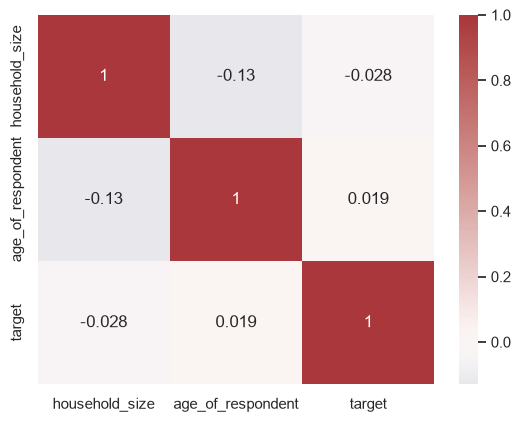

In [10]:
# Kategoriale Features: Cramér's V (0 = kein, 1 = perfekter Zusammenhang)
def cramers_v(a, b):
    tab = pd.crosstab(a, b)
    chi2 = chi2_contingency(tab)[0]
    n = tab.values.sum()
    return np.sqrt(chi2 / (n * (min(tab.shape) - 1)))

assoc = pd.Series({c: cramers_v(train[c], train["target"]) for c in cat_cols})
display(assoc.sort_values(ascending=False))

# Numerische Features: Korrelation
sns.heatmap(train[["household_size", "age_of_respondent", "target"]].corr(),
            annot=True, cmap="vlag", center=0)
plt.savefig(FIG + "04_korrelation_numerisch.png", dpi=200)
plt.show()

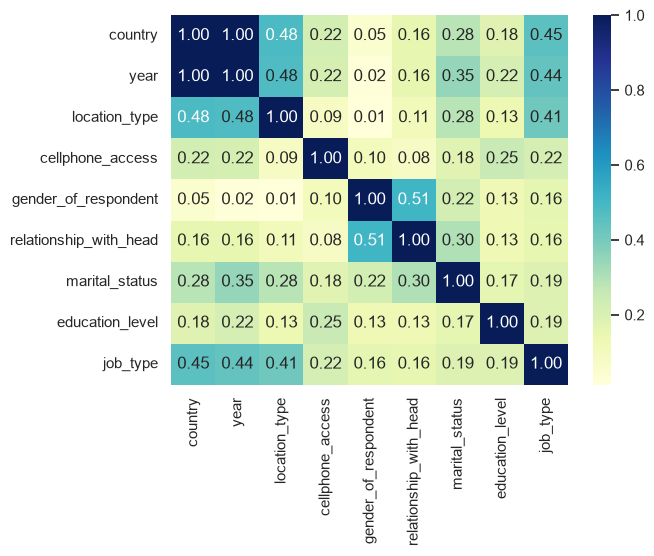

In [11]:
m = pd.DataFrame([[cramers_v(train[a], train[b]) for b in cat_cols] for a in cat_cols],
                 index=cat_cols, columns=cat_cols)
sns.heatmap(m, annot=True, fmt=".2f", cmap="YlGnBu")
plt.savefig(FIG + "05_cramers_v_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

## Fazit: Zusammenhänge messen

### Rangfolge der kategorialen Features (Cramér's V mit der Zielvariable)

| Rang | Feature | Cramér's V | Einordnung |
|---|---|---|---|
| 1 | education_level | 0,388 | mittel bis stark |
| 2 | job_type | 0,359 | mittel bis stark |
| 3 | cellphone_access | 0,210 | klein bis mittel |
| 4 | country | 0,189 | klein bis mittel |
| 5 | year | 0,144 | klein (redundant, siehe unten) |
| 6 | relationship_with_head | 0,118 | klein |
| 7 | gender_of_respondent | 0,117 | klein |
| 8 | marital_status | 0,091 | sehr klein |
| 9 | location_type | 0,087 | sehr klein |

**Befund:** Bildung und Berufstyp sind mit Abstand die stärksten Einflussfaktoren, danach folgen Handyzugang und Land. Die Rangfolge deckt sich mit den Unterschieden der Gruppenquoten aus Schritt 6 (Faktor 15 bei Bildung, Faktor 37 beim Beruf). Geschlecht und Stadt/Land haben trotz sichtbarer Quotenunterschiede (8,3 bzw. 6,2 Prozentpunkte) nur schwache Zusammenhänge. Die Plätze 6 und 7 (0,118 und 0,117) liegen praktisch gleichauf und sollten nicht gegeneinander interpretiert werden.

### Numerische Features

| Paar | Korrelation |
|---|---|
| household_size ↔ target | -0,028 |
| age_of_respondent ↔ target | 0,019 |
| household_size ↔ age_of_respondent | -0,13 |

Beide numerischen Features hängen **linear praktisch nicht** mit dem Bankkonto zusammen (|r| < 0,03). Haushaltsgröße und Alter sind untereinander leicht negativ korreliert (ältere Befragte leben tendenziell in kleineren Haushalten), das ist schwach. **Einschränkung:** Die Korrelation misst nur lineare Zusammenhänge. Ein nichtlinearer Effekt, etwa eine höhere Quote in mittleren Altersgruppen, bleibt dabei unsichtbar. Das prüfen wir über die Quote nach Altersgruppen.

### Überlappungen zwischen den Features (Cramér's V Matrix)

**Vollständige Redundanz:**
- **country ↔ year = 1,00.** Jedes Land wurde offenbar in genau einem Jahr befragt, das Jahr ist damit vollständig durch das Land bestimmt. `year` liefert keine zusätzliche Information. Der V-Wert von year mit dem Ziel (0,144) ist nur ein abgeschwächter Länderefekt, weil Kenia und Uganda im selben Jahr liegen. (Mit `pd.crosstab(train["country"], train["year"])` bestätigen.)

**Starke Überlappungen (V ≥ 0,4):**
- gender_of_respondent ↔ relationship_with_head: 0,51. Die Stellung im Haushalt hängt stark vom Geschlecht ab.
- country ↔ location_type: 0,48. Der Stadt/Land-Anteil unterscheidet sich deutlich zwischen den Ländern.
- country ↔ job_type: 0,45 und location_type ↔ job_type: 0,41. Die Berufsstruktur unterscheidet sich nach Land und nach Stadt/Land.

**Mittlere Überlappungen (V = 0,2 bis 0,35):**
- marital_status ↔ year/country (0,35 bzw. 0,28), ↔ relationship_with_head (0,30), ↔ location_type (0,28)
- cellphone_access ↔ education_level (0,25), ↔ country (0,22), ↔ job_type (0,22)

**Geringe Überlappung:** education_level und job_type, die beiden stärksten Einflussfaktoren, hängen untereinander nur schwach zusammen (V = 0,19). Sie liefern damit weitgehend **unabhängige Information** und ergänzen sich im Modell.

### Einschränkungen
- Cramér's V zeigt die **Stärke, nicht die Richtung** des Zusammenhangs. Die Richtung entnehmen wir den Gruppenquoten aus Schritt 6.
- Der Wert wird bei vielen Kategorien und kleinen Zellen leicht überschätzt, bei job_type (10 Kategorien) und education_level (6) ist das relevant. Die Rangfolge ist daher eine Orientierung, kein exakter Wichtigkeitswert.
- Es handelt sich um **bivariate** Zusammenhänge. Wegen der Überlappungen (z. B. Land ↔ Beruf, Geschlecht ↔ Haushaltsstellung) kann ein Effekt teilweise durch ein anderes Merkmal erklärt werden. Ob er bestehen bleibt, zeigen erst die Modelle (Feature Importance, SHAP) und die Interaktionsanalyse.

### Konsequenzen für Preprocessing und Modellierung
- **year entfernen** (oder nur eines der beiden Features nutzen), da es durch country vollständig bestimmt ist. country behalten, weil es mehr Information trägt.
- **Education und job_type** als zentrale Features behalten. Seltene Kategorien vorher zusammenfassen.
- **gender_of_respondent und relationship_with_head** gemeinsam betrachten. Bei linearen Modellen auf Multikollinearität achten, baumbasierte Modelle sind unempfindlicher. Prüfen, ob relationship_with_head über das Geschlecht hinaus etwas beiträgt.
- **household_size und age_of_respondent** nicht aussortieren: Lineare Korrelationen nahe null schließen nichtlineare oder interaktive Effekte nicht aus. Altersgruppen und Interaktionen zuerst prüfen.
- **Interaktionen** im nächsten Schritt gezielt untersuchen: Bildung × Land, Handyzugang × Bildung, Geschlecht × Jobtyp, Stadt/Land × Land.

# 8. Interaktionen
##### Ziel: prüfen, ob sich Effekte je nach Gruppe unterscheiden (z. B. wirkt Bildung in Kenia anders als in Tansania).

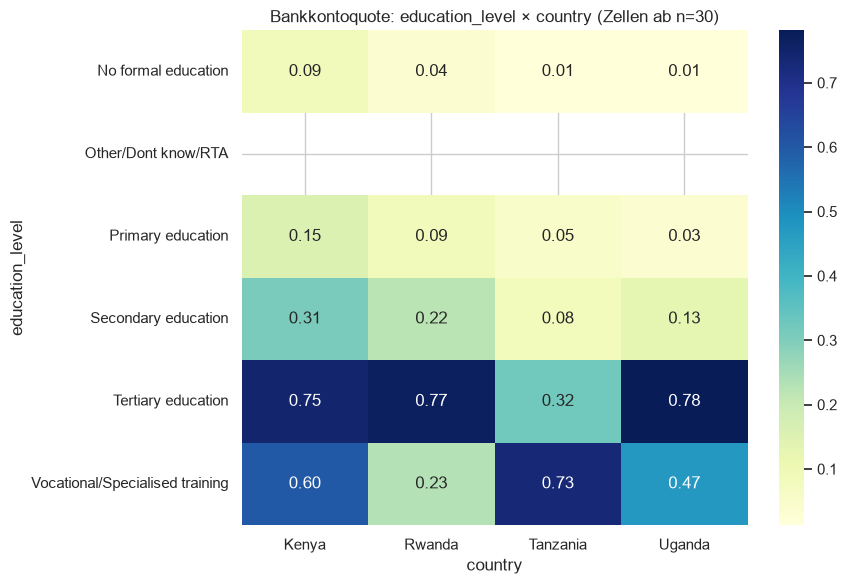

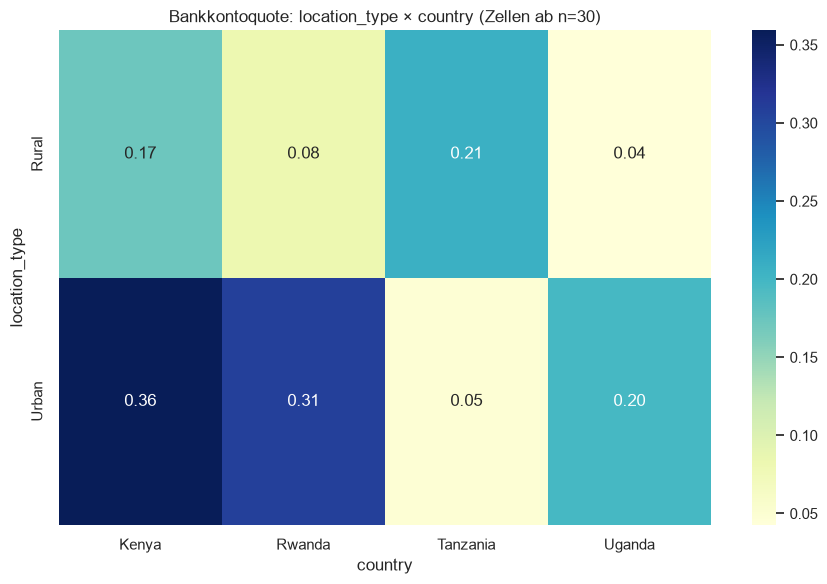

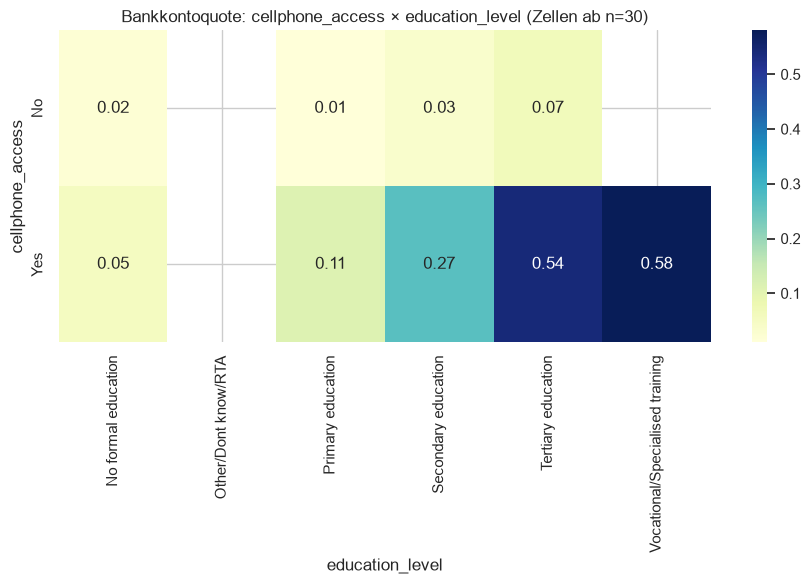

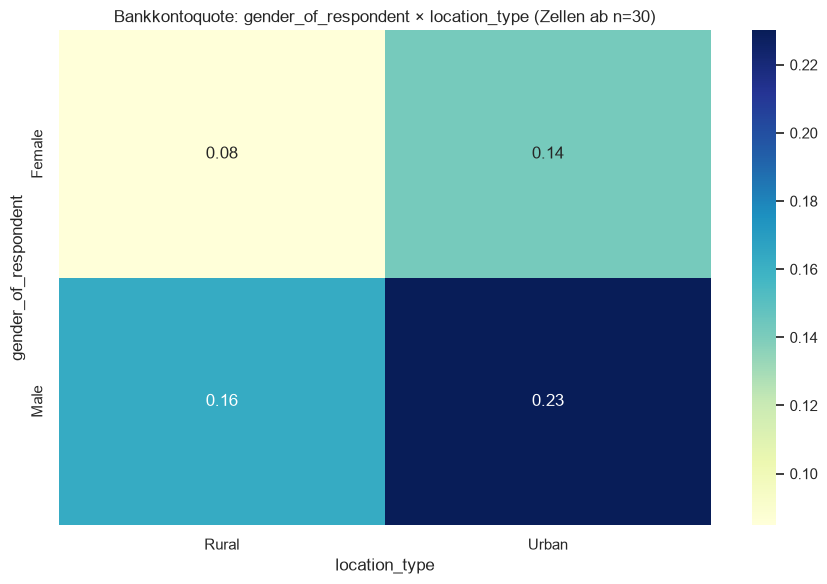

In [12]:
def interaction(row, col, min_n=30):
    piv = train.pivot_table(index=row, columns=col, values="target", aggfunc="mean")
    cnt = train.pivot_table(index=row, columns=col, values="target", aggfunc="size")
    plt.figure(figsize=(9, 6))
    sns.heatmap(piv.where(cnt >= min_n), annot=True, fmt=".2f", cmap="YlGnBu")
    plt.title(f"Bankkontoquote: {row} × {col} (Zellen ab n={min_n})")
    plt.tight_layout()
    plt.savefig(FIG + f"06_interaktion_{row}_{col}.png", dpi=200)
    plt.show()

interaction("education_level", "country")
interaction("location_type", "country")
interaction("cellphone_access", "education_level")
interaction("gender_of_respondent", "location_type")

## Fazit: Interaktionen

**Vorgehen:** Bankkontoquote für Kombinationen von zwei Merkmalen, Zellen mit weniger als 30 Personen sind ausgeblendet (weiße Felder). Jede Heatmap hat eine eigene Farbskala, verglichen werden daher die Zahlen und nicht die Farben.

### 1. Bildung × Land

| Bildung | Kenia | Ruanda | Tansania | Uganda |
|---|---|---|---|---|
| Keine formale Bildung | 0,09 | 0,04 | 0,01 | 0,01 |
| Grundschule | 0,15 | 0,09 | 0,05 | 0,03 |
| Sekundarbildung | 0,31 | 0,22 | 0,08 | 0,13 |
| Tertiary | 0,75 | 0,77 | 0,32 | 0,78 |
| Vocational | 0,60 | 0,23 | 0,73 | 0,47 |

- **Der Bildungseffekt gilt in allen vier Ländern.** Von "keine formale Bildung" bis Tertiary steigt die Quote in Kenia um 66, in Ruanda um 73, in Uganda um 77 und in Tansania um 31 Prozentpunkte. Der Effekt ist also kein Nebenprodukt des Ländereffekts.
- **Der Ländereffekt hängt vom Bildungsniveau ab.** Auf niedrigen Bildungsstufen liegt Kenia klar vorn (Grundschule: Kenia 0,15 gegenüber Uganda 0,03). Auf Tertiary-Niveau gleichen sich Kenia, Ruanda und Uganda dagegen fast an (0,75 bis 0,78). Der Länderunterschied aus Schritt 6 entsteht also überwiegend bei niedriger und mittlerer Bildung.
- **Auffälligkeiten:**
  - Tansania weicht ab: Tertiary erreicht dort nur 0,32, Vocational aber 0,73. Das ist das einzige Land, in dem Berufsausbildung klar über Hochschulbildung liegt.
  - In Ruanda ist es umgekehrt: Tertiary 0,77, Vocational nur 0,23.
  - Die hohe Gesamtquote von Vocational (57 %, Schritt 6) kommt also vor allem aus Kenia, Tansania und Uganda und ist nicht in allen Ländern gleich.
  - Diese Zellen sind teils klein, die Ausreißer sollten vor einer Interpretation mit den Fallzahlen geprüft werden.
- Die Kategorie "Other/Dont know/RTA" ist in allen Ländern ausgeblendet (n < 30).

### 2. Stadt/Land × Land

| | Kenia | Ruanda | Tansania | Uganda |
|---|---|---|---|---|
| Rural | 0,17 | 0,08 | 0,21 | 0,04 |
| Urban | 0,36 | 0,31 | 0,05 | 0,20 |

- **Der Stadtvorteil gilt nur in drei von vier Ländern:** Kenia 0,17 → 0,36, Ruanda 0,08 → 0,31, Uganda 0,04 → 0,20.
- **Tansania kehrt das Muster um:** Auf dem Land liegt die Quote bei 0,21, in der Stadt nur bei 0,05. Außerdem hat Tansania auf dem Land die höchste Quote aller Länder (vor Kenia).
- Damit ist die Aussage "Städter haben häufiger ein Konto" aus Schritt 6 nur im Durchschnitt richtig und trifft nicht für jedes Land zu. Der geringe Gesamtunterschied zwischen Stadt und Land (Cramér's V = 0,087) kommt auch daher, dass sich die Effekte in den Ländern teilweise aufheben.
- **Die Tansania-Auffälligkeit muss geprüft werden.** Ein solches Umkehrmuster ist ungewöhnlich und könnte auf Besonderheiten der Stichprobe oder der Kodierung zurückgehen. Fallzahlen pro Zelle ansehen und im Bericht vorsichtig formulieren.

### 3. Handyzugang × Bildung

| Bildung | Kein Handyzugang | Handyzugang |
|---|---|---|
| Keine formale Bildung | 0,02 | 0,05 |
| Grundschule | 0,01 | 0,11 |
| Sekundarbildung | 0,03 | 0,27 |
| Tertiary | 0,07 | 0,54 |
| Vocational | n < 30 | 0,58 |

- **Ohne Handyzugang liegt die Quote auf jeder Bildungsstufe nahe null** (maximal 0,07, selbst bei Tertiary). Bildung allein reicht also nicht.
- **Mit Handyzugang zeigt sich der volle Bildungseffekt:** von 0,05 (keine Bildung) bis 0,54 bzw. 0,58 (Tertiary bzw. Vocational).
- Das ist eine **starke Interaktion**: Der Bildungseffekt wirkt fast nur bei Befragten mit Handyzugang, und umgekehrt hilft Handyzugang bei niedriger Bildung kaum (0,05 bei keiner formalen Bildung). Beide Bedingungen zusammen unterscheiden die Gruppen am besten.
- Die Zellen ohne Handyzugang und mit höherer Bildung sind vermutlich klein. Die Quote von 0,07 bei Tertiary ist daher unsicher.

### 4. Geschlecht × Stadt/Land

| | Rural | Urban |
|---|---|---|
| Frauen | 0,08 | 0,14 |
| Männer | 0,16 | 0,23 |

- **Der Geschlechterunterschied besteht in beiden Gebieten:** ca. 8 Prozentpunkte auf dem Land (0,08 vs. 0,16, Männer etwa doppelt so häufig) und ca. 9 Prozentpunkte in der Stadt (0,14 vs. 0,23).
- **Der Stadtvorteil ist bei beiden Geschlechtern ähnlich groß** (Frauen +6, Männer +7 Prozentpunkte). Das Muster ist weitgehend additiv, es gibt keine starke Interaktion.
- Am niedrigsten ist die Quote bei Frauen auf dem Land (0,08), am höchsten bei Männern in der Stadt (0,23). Der Geschlechterunterschied lässt sich also nicht allein durch Stadt/Land erklären. Ob er nach Berücksichtigung von Bildung, Beruf und Land bestehen bleibt, zeigt erst das Modell.

### Zusammenfassung der Interaktionen

| Kombination | Stärke der Interaktion | Kernaussage |
|---|---|---|
| Handyzugang × Bildung | stark | Bildung wirkt fast nur mit Handyzugang |
| Stadt/Land × Land | stark (Tansania gegenläufig) | Stadtvorteil gilt nicht in allen Ländern |
| Bildung × Land | mittel bis stark | Länderunterschied vor allem bei niedriger Bildung, Tansania abweichend |
| Geschlecht × Stadt/Land | gering | Beide Effekte wirken weitgehend unabhängig |

### Einschränkungen
- **Fallzahlen:** Die Maske blendet nur Zellen unter 30 aus. Zellen mit 30 bis ca. 100 Personen sind weiterhin sehr unsicher (z. B. Tertiary und Vocational pro Land). Konkrete Prozentwerte daraus nicht überinterpretieren.
- **Nur zwei Merkmale gleichzeitig:** Weitere Faktoren (z. B. Beruf) sind nicht kontrolliert. Teile der Effekte können durch dritte Merkmale erklärt werden.
- **Zusammenhang, keine Ursache.**

### Konsequenzen fürs Modell
- **Baumbasierte Modelle** (Random Forest, XGBoost, LightGBM) erkennen solche Interaktionen automatisch. Für **Logistic Regression** sollten wir sie explizit ergänzen, z. B. als kombinierte Features:
  - `education_level × country`
  - `cellphone_access × education_level`
  - `location_type × country`
- Zusätzlich lohnt sich ein einfaches Feature "Handyzugang und mindestens Sekundarbildung".
- Die **Tansania-Auffälligkeiten** (Stadt/Land umgekehrt, Tertiary niedrig) sprechen für Länder-Interaktionen im Modell und für eine Prüfung der Daten dieses Landes.
- Geschlecht und Stadt/Land können als eigenständige Haupteffekte im Modell bleiben, eine eigene Interaktion ist nach dieser Auswertung nicht nötig.

# 9. Top-5-Erkenntnisse festhalten
##### Ziel: die EDA in berichtsreife Aussagen übersetzen.

## 9. Top-5-Erkenntnisse und Übergabe an das Preprocessing

### Top-5-Erkenntnisse

| # | Erkenntnis | Abbildung | Beleg | Konsequenz fürs Modell |
|---|---|---|---|---|
| 1 | **Bildung ist der stärkste Einflussfaktor und wirkt in allen vier Ländern.** Die Quote steigt von "keine Bildung" bis Tertiary/Vocational um ein Vielfaches. | `03_quote_education_level.png`, `06_interaktion_education_level_country.png` | 3,9 % (keine formale Bildung) → 8,5 % (Grundschule) → 23,3 % (Sekundar) → 51,1 % (Tertiary) / 57,0 % (Vocational). Cramér's V = 0,39 (Rang 1). Anstieg von "keine Bildung" bis Tertiary: Kenia +66, Ruanda +73, Uganda +77, Tansania +31 Prozentpunkte. | Feature zentral behalten. Reihenfolge ist nicht streng monoton (Vocational > Tertiary, Tansania und Ruanda gegenläufig), deshalb nicht blind ordinal kodieren, sondern One-Hot oder baumbasiert nutzen. |
| 2 | **Der Berufstyp trennt die Gruppen am stärksten, aber die Kontoinhaber stammen überwiegend aus Gruppen mit niedriger Quote.** | `03_quote_job_type.png` | Formal angestellt (Staat) 77,5 %, formal (privat) 54,1 % gegenüber informell 7,9 % und kein Einkommen 2,1 %. Cramér's V = 0,36 (Rang 2). Formal Angestellte stellen nur ca. 26 % der Kontoinhaber (871 von 3.312). | Feature behalten. Seltene Kategorien vor dem Modellieren behandeln. Da Bildung und Beruf nur schwach zusammenhängen (V = 0,19), ergänzen sie sich. |
| 3 | **Handyzugang ist praktisch Voraussetzung für ein Bankkonto, reicht aber allein nicht.** Bildung wirkt fast nur bei vorhandenem Handyzugang. | `03_quote_cellphone_access.png`, `06_interaktion_cellphone_access_education_level.png` | 1,7 % (kein Handy) gegenüber 18,4 % (Handy). Ca. 97 % aller Kontoinhaber haben Handyzugang. Ohne Handy liegt die Quote auf jeder Bildungsstufe bei höchstens 7 %, mit Handy steigt sie auf 54 % (Tertiary) bzw. 58 % (Vocational). | Feature behalten und als Interaktion mit Bildung ergänzen (für Logistic Regression explizit). Mögliche Stellvertreter-Rolle für Einkommen und Infrastruktur im Bericht erwähnen. |
| 4 | **Länder- und Stadt/Land-Effekte sind nicht einheitlich.** Kenia liegt vorn, und der Stadtvorteil gilt nicht überall. | `03_quote_country.png`, `06_interaktion_location_type_country.png` | Kenia 25,1 % gegenüber Uganda 8,6 %. Kenia stellt 26 % der Befragten, aber ca. 46 % der Kontoinhaber. Stadt vs. Land: Kenia 0,36/0,17, Ruanda 0,31/0,08, Uganda 0,20/0,04, aber **Tansania umgekehrt** (Stadt 0,05, Land 0,21). | Land-Interaktionen (Land × Bildung, Land × Stadt/Land) als Features testen. Tansania-Befund mit Fallzahlen prüfen, bevor er im Bericht genannt wird. |
| 5 | **Frauen haben deutlich seltener ein Konto, unabhängig von Stadt und Land.** | `03_quote_gender_of_respondent.png`, `06_interaktion_gender_of_respondent_location_type.png` | Männer 19,0 % gegenüber Frauen 10,7 % (8,3 Prozentpunkte). Auf dem Land 0,16 vs. 0,08, in der Stadt 0,23 vs. 0,14. Frauen stellen 59 % der Befragten, aber nur ca. 45 % der Kontoinhaber. Cramér's V = 0,12 (schwach). | Feature behalten, aber nicht überinterpretieren. Ob der Unterschied nach Kontrolle von Bildung, Beruf und Land bestehen bleibt, klärt das Modell (SHAP). Für den Bericht und einen möglichen Fairness-Check relevant. |

**Rahmenbefund (gilt für alles Weitere):** Die Zielvariable ist stark unausgewogen, nur **14,1 %** (3.312 von 23.524) haben ein Konto. Ein Modell, das immer "No" sagt, erreicht schon 85,9 % Accuracy (`00_zielvariable.png`). Metriken wie F1, Precision/Recall der Klasse "Yes" und PR-AUC sind daher Pflicht, Splits müssen stratifiziert und gemischt sein (die Daten sind nach Land sortiert).

### Entscheidungen für das Preprocessing

**Kategorien zusammenfassen**

| Feature | Kategorie | n | Entscheidung |
|---|---|---|---|
| education_level | Other/Dont know/RTA | 35 | In "Unbekannt/Sonstige" überführen. Die Quote von 31,4 % ist bei dieser Größe nicht interpretierbar. |
| job_type | Dont Know/Refuse to answer | 126 | Mit "Unbekannt/Sonstige" zusammenfassen. |
| job_type | Government Dependent | 247 | **Nicht** mit "Formally employed Government" zusammenlegen (Quoten 20,2 % vs. 77,5 %). Entweder separat lassen (Baummodelle kommen mit n = 247 zurecht) oder für lineare Modelle mit Gruppen wie "Other Income" bündeln. Per Cross-Validation entscheiden. |
| marital_status, relationship_with_head | "Dont know" bzw. "Other non-relatives" | [n ergänzen] | Sehr klein, mit der nächstpassenden Restkategorie zusammenfassen. |
| education_level | Tertiary und Vocational | 1.157 / 803 | **Nicht** zusammenfassen: Ihre Quoten unterscheiden sich je nach Land stark. |

**Redundante oder überlappende Features**
- **year entfernen** (country ↔ year: Cramér's V = 1,00, das Jahr ist durch das Land vollständig bestimmt).
- **gender_of_respondent ↔ relationship_with_head** (V = 0,51): beide zunächst behalten, bei linearen Modellen auf Multikollinearität achten und prüfen, ob relationship_with_head über das Geschlecht hinaus etwas beiträgt.
- country ↔ location_type (0,48) und country ↔ job_type (0,45): moderate Überlappung, Features bleiben.
- `uniqueid` ausschließen, `bank_account` in 0/1 umkodieren, ebenso cellphone_access, location_type und gender.

**Numerische Features**
- household_size und age_of_respondent haben praktisch keine lineare Korrelation mit dem Ziel (-0,03 bzw. 0,02), werden aber **nicht** aussortiert, da nichtlineare Effekte möglich sind.
- Ausreißer (Haushalt ab ca. 10 Personen, Alter ab ca. 84 Jahren) bleiben erhalten, da plausibel. Für lineare Modelle ggf. Kappung oder log-Transformation von household_size prüfen.
- Altersgruppen als zusätzliche Variante bilden. [Ergebnis der Quote nach Altersgruppen ergänzen]

**Interaktionen als neue Features (vor allem für Logistic Regression)**
- `education_level × country`
- `cellphone_access × education_level` (oder ein Flag "Handyzugang und mindestens Sekundarbildung")
- `location_type × country`
- Nicht nötig: Geschlecht × Stadt/Land (weitgehend additiv).

**Gruppen mit zu wenig Daten für verlässliche Aussagen**
- Einzelne Kategorien: Other/Dont know/RTA (n = 35), Dont Know/Refuse (n = 126), Government Dependent (n = 247).
- Zellen der Interaktionsanalysen unter ca. 100 Personen (v. a. Tertiary/Vocational pro Land, höhere Bildung ohne Handyzugang). Quoten dort im Bericht nicht als belastbare Befunde nennen.
- Bei allen Gruppenquoten immer die Fallzahl mit angeben.

### Offene Punkte vor Abschluss der EDA
- Tansania-Befunde (Stadt/Land umgekehrt, Tertiary nur 0,32) mit Fallzahlen prüfen: `pd.crosstab(train["location_type"], train["country"])`.
- Bestätigen, dass jedes Land nur in einem Jahr befragt wurde: `pd.crosstab(train["country"], train["year"])`.
- Quote nach Altersgruppen ergänzen und das Fazit zu Schritt 7 und 8 danach nochmals abgleichen.

### Limitationen für den Bericht
- Alle Befunde sind bivariate Zusammenhänge, keine Ursachen. Merkmale überlappen (Bildung, Beruf, Handyzugang, Land), ein Effekt kann teilweise durch ein anderes Merkmal erklärt werden.
- Die Stichprobe ist nicht repräsentativ (Frauen, Landbevölkerung und niedrige Bildung überrepräsentiert, Uganda klein).
- Länder- und Jahreseffekte lassen sich nicht trennen.
- Es gibt keine Einkommensdaten, Handyzugang und Berufstyp stehen teils stellvertretend dafür.